In [1]:
import numpy as np
import matplotlib as plt
import copy
import time

from qiskit import QuantumCircuit

from qiskit_aer import AerSimulator

from qiskit.visualization import plot_histogram

In [2]:
#Creating bell circuit
circuit = QuantumCircuit(2) #quantum circuit with two qubits

circuit.h(0)
circuit.cx(0,1)

print(circuit)

     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


In [3]:
simulator = AerSimulator(method="statevector")

In [4]:
statevector = circuit.copy()

statevector.save_statevector()

result = simulator.run(statevector).result()
statevector = result.data(0)["statevector"]

print(statevector)

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


In [5]:
print("Final statevector:")

for index, amplitude in enumerate(statevector.data):
    basis_state = format(index, f"0{statevector.num_qubits}b")
    print(f"    |{basis_state}⟩: {amplitude:.4f}")

Final statevector:
    |00⟩: 0.7071+0.0000j
    |01⟩: 0.0000+0.0000j
    |10⟩: 0.0000+0.0000j
    |11⟩: 0.7071+0.0000j


In [6]:
probs = circuit.copy()

probs.save_probabilities()

result = simulator.run(probs).result()
probabilities = result.data(0)["probabilities"]

print("Exact measurement probabilities:")

Exact measurement probabilities:


In [7]:
for index, probability in enumerate(probabilities):
    basis_state = format(index, f"0{probs.num_qubits}b")
    print(f"    P({basis_state}) = {probability:.4f}")

    P(00) = 0.5000
    P(01) = 0.0000
    P(10) = 0.0000
    P(11) = 0.5000


In [8]:
shots = 1000

counts = circuit.copy()
counts.measure_all()

result = simulator.run(counts, shots=shots).result()
counts = result.get_counts()

print(counts)

{'00': 511, '11': 489}


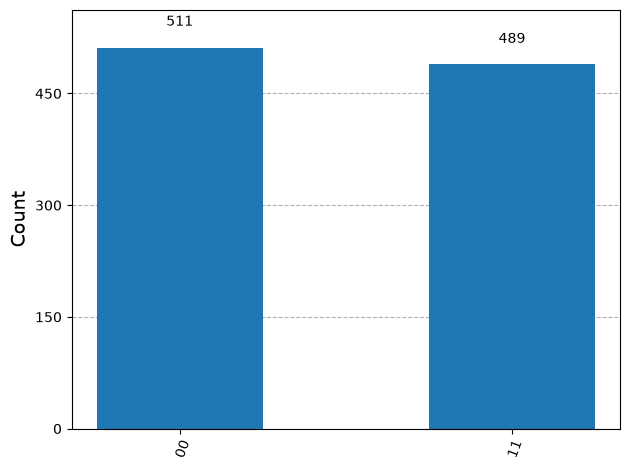

In [9]:
# Visualize the sampled outcomes
plot_histogram(counts)

In [11]:
from qiskit.quantum_info import Pauli

expectation = circuit.copy()

observable = Pauli("ZZ")

expectation.save_expectation_value(
    observable,
    qubits = [0,1],
    label = "expectation_value"
)

result = simulator.run(expectation).result()
expectation_value = result.data(0)["expectation_value"]

print("Observable: ZZ")
print(f"Expectation value: {expectation_value:.4f}")

Observable: ZZ
Expectation value: 1.0000
